In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

In [2]:
# Load dataset
vocab_size = 5000
max_length = 100

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

# Pad sequences to equal length
X_train = pad_sequences(
    X_train, maxlen=max_length
)

X_test = pad_sequences(
    X_test, maxlen=max_length
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000


In [3]:
# Load dataset
vocab_size = 5000
max_length = 100

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

# Pad sequences to equal length
X_train = pad_sequences(
    X_train, maxlen=max_length
)

X_test = pad_sequences(
    X_test, maxlen=max_length
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 25000
Testing samples: 25000


In [4]:
model = Sequential([
    Embedding(vocab_size, 32, input_length=max_length),
    LSTM(32),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.7700 - loss: 0.4695 - val_accuracy: 0.8374 - val_loss: 0.3627
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8713 - loss: 0.3043 - val_accuracy: 0.8524 - val_loss: 0.3398
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8966 - loss: 0.2553 - val_accuracy: 0.8468 - val_loss: 0.3525


In [6]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(accuracy * 100, 2), "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8476 - loss: 0.3561
Test Loss: 0.3561
Test Accuracy: 84.76 %


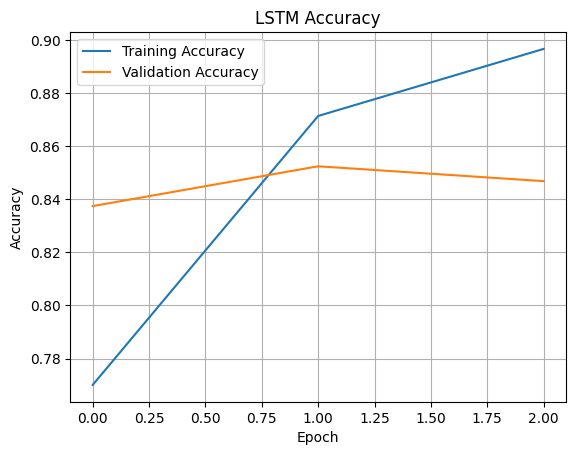

In [7]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Accuracy")
plt.legend()
plt.grid()
plt.show()

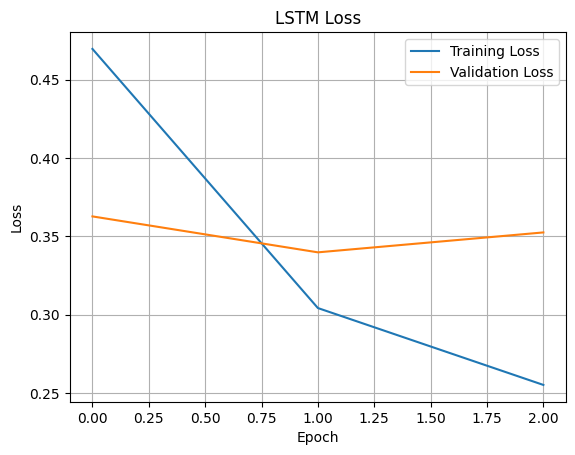

In [8]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Loss")
plt.legend()
plt.grid()
plt.show()

In [9]:
# Convert word IDs back to readable text
word_index = imdb.get_word_index()

word_index = {
    word: index + 3 for word, index in word_index.items()
}

word_index["<PAD>"] = 0
word_index["<START>"] = 1
word_index["<UNK>"] = 2
word_index["<UNUSED>"] = 3

reverse_word_index = {
    index: word for word, index in word_index.items()
}

def decode_review(sequence):
    return " ".join(
        reverse_word_index.get(word, "?")
        for word in sequence
        if word > 3
    )

# Predict first 5 test reviews
predictions = model.predict(X_test[:5])

for i in range(5):
    sentiment = "Positive" if predictions[i][0] >= 0.5 else "Negative"

    print("Review:", decode_review(X_test[i])[:300])
    print("Actual:", "Positive" if y_test[i] == 1 else "Negative")
    print("Predicted:", sentiment)
    print("Confidence:", round(float(predictions[i][0]) * 100, 2), "%")
    print("-" * 50)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step
Review: please give this one a miss br br and the rest of the cast terrible performances the show is flat flat flat br br i don't know how michael could have allowed this one on his he almost seemed to know this wasn't going to work out and his performance was quite so all you fans give this a miss
Actual: Negative
Predicted: Negative
Confidence: 21.61 %
--------------------------------------------------
Review: a powerful study of sexual and desperation be patient up the atmosphere and pay attention to the wonderfully written script br br i praise robert this is one of his many films that deals with fascinating subject matter this film is disturbing but it's sincere and it's sure to a strong emotional resp
Actual: Positive
Predicted: Positive
Confidence: 98.72 %
--------------------------------------------------
Review: the of that civil war it would be easy to see this as a about those events may 

In [10]:
# Convert word IDs back to readable text
word_index = imdb.get_word_index()

word_index = {
    word: index + 3 for word, index in word_index.items()
}

word_index["<PAD>"] = 0
word_index["<START>"] = 1
word_index["<UNK>"] = 2
word_index["<UNUSED>"] = 3

reverse_word_index = {
    index: word for word, index in word_index.items()
}

def decode_review(sequence):
    return " ".join(
        reverse_word_index.get(word, "?")
        for word in sequence
        if word > 3
    )

# Predict first 5 test reviews
predictions = model.predict(X_test[:5])

for i in range(5):
    sentiment = "Positive" if predictions[i][0] >= 0.5 else "Negative"

    print("Review:", decode_review(X_test[i])[:300])
    print("Actual:", "Positive" if y_test[i] == 1 else "Negative")
    print("Predicted:", sentiment)
    print("Confidence:", round(float(predictions[i][0]) * 100, 2), "%")
    print("-" * 50)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Review: please give this one a miss br br and the rest of the cast terrible performances the show is flat flat flat br br i don't know how michael could have allowed this one on his he almost seemed to know this wasn't going to work out and his performance was quite so all you fans give this a miss
Actual: Negative
Predicted: Negative
Confidence: 21.61 %
--------------------------------------------------
Review: a powerful study of sexual and desperation be patient up the atmosphere and pay attention to the wonderfully written script br br i praise robert this is one of his many films that deals with fascinating subject matter this film is disturbing but it's sincere and it's sure to a strong emotional resp
Actual: Positive
Predicted: Positive
Confidence: 98.72 %
--------------------------------------------------
Review: the of that civil war it would be easy to see this as a about those events may or may not have had in mind when he made but whate